In [18]:
import meep as mp
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# BƯỚC CHUẨN BỊ: XỬ LÍ ẢNH BẰNG OPENCV

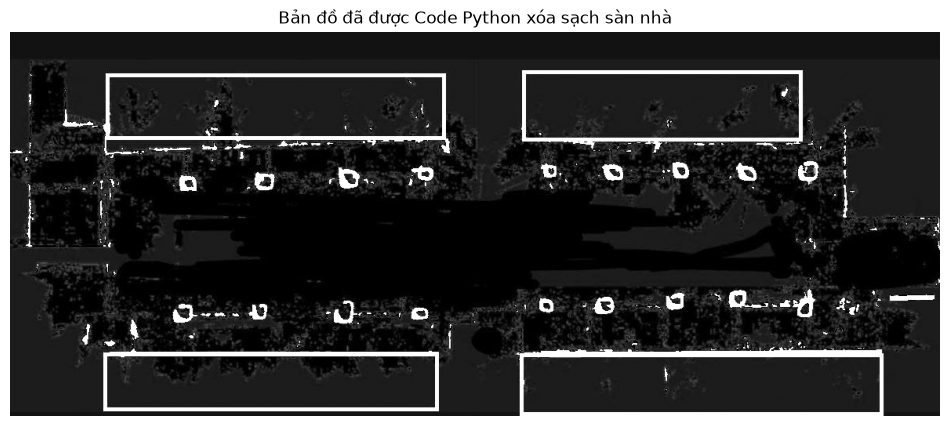

[*] Đã lưu file 'cleaned_floor_map.jpg' thành công!


In [19]:
import os
import cv2
from pathlib import Path

# 1. Đọc ảnh đã ghép (Ảnh gốc đang có sàn nhà màu xám)
root = Path.cwd().resolve()
if "notebooks" in str(root):
    root = root.parent
image_path = root / "data" / "processed" / "full_campus_pro.jpg"
img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# 2. Xóa mảng xám sàn nhà (Bước 1 của bạn)
# Lọc toàn bộ các pixel có giá trị từ 90 đến 150 và gán bằng 0 (Đen tuyệt đối)
img[(img >= 90) & (img <= 150)] = 0

# 3. Khuếch đại nét tường (Tùy chọn giúp MEEP nhận diện dễ hơn)
# Ép các nét màu sáng (tường/kính) trở nên trắng rõ rệt hơn
img[img > 150] = 255

# 4. Hiển thị ảnh để kiểm tra kết quả
plt.figure(figsize=(12, 8))
plt.imshow(img, cmap='gray')
plt.title("Bản đồ đã được Code Python xóa sạch sàn nhà")
plt.axis('off')
plt.show()

# 5. Lưu ảnh mới để mang lên Canva làm tiếp Bước 2 & 3
save_dir = root/"data"/"processed"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(save_dir, 'cleaned_floor_map.jpg')
cv2.imwrite(save_path, img)
print("[*] Đã lưu file 'cleaned_floor_map.jpg' thành công!")

# BƯỚC 1: ĐỌC BẢN QUÉT LIDAR (FLOOR PLAN)
1. Đọc ảnh và chuyển thành ảnh xám (Grayscale)
2. Cắt bỏ phần dưới của hình (chứa các thông số kỹ thuật) để quét nhầm thành tường
3. Từ bức ảnh sau khi cắt phần dưới --> resize lại với mức độ phân giải (RESOLUTION) mong muốn
4. Từ bức ảnh đã được resized, xoay trục để khớp với lưới tính toán của MEEP
5. Khởi tạo ma trận epsilon (mặc định không khí có epsilon = 1)
6. Gán giá trị epsilon cho các phần tử: cửa kính, tường bê tông (dựa trên độ sáng phần tử trên ma trận)

In [20]:
# Kích thước thực tế của trường quét bằng LiDAR
SX, SY = 40.0, 20.0
RESOLUTION = 6 # Độ phân giải FDTD (6 pixels / 1 met thực tế)
cell = mp.Vector3(SX,SY,0)

def create_school_map_from_polycam(image_path,sx, sy, res):
    """
    Khi có ảnh Floorplan xuất từ Polycam, đọc ảnh và chuyển thành ma trận chiết suất.
    """
    # 1. Đọc ảnh mặt bằng của Polycam ('L': Chuyển về ảnh xám Grayscale)
    # Dựa vào độ sáng để xác định tường học không gian phòng.
    img = Image.open(image_path).convert('L')
    width, height = img.size
    
    # 2. Cắt bỏ 12% chiều cao của hình (tránh đọc nhầm dòng chữ ở dưới)
    img_cropped = img.crop((0,0,width,int(height*0.88)))
    
    # 3. Resize lại khung hình để khớp với lưới tính toán của MEEP
    grid_width, grid_height = int(sx * res), int(sy * res) # Độ phân giải bản đồ vật liệu
    img_resized = img_cropped.resize((grid_width, grid_height))
    
    # 4. Xoay trục ảnh vừa được resized để khớp với trục (X,Y) của MEEP
    img_arr = np.flipud(np.array(img_resized)).T
    
    # 5. Khởi tạo ma trận: Mặc định toàn bộ là không khí (epsilon = 1.0)
    eps_map = np.zeros((grid_width, grid_height), dtype=np.float32)
    
    # Ta dùng ảnh NỀN ĐEN
    # Pixel tối (~0)-> nền / không gian trống:      ID = 0.0
    # Pixel vừa (>25)-> cửa gỗ/kính (eps = 2.5)     ID = 1.0
    # Pixel sáng (>80)-> tường bê tông (eps = 6.25) ID = 2.0
    eps_map[img_arr > 25] = 1.0         # Cửa kính / Vách gỗ (ID = 1)
    eps_map[img_arr > 80] = 2.0         # Tường bê tông cốt thép (ID = 2)
        
    return eps_map

# Xác định ma trận trích suất từ ảnh của Polycam
img_path = root/"data"/"processed"/"cleaned_floor_map.jpg"
eps_matrix = create_school_map_from_polycam(img_path, SX, SY, RESOLUTION) 

# BƯỚC 2: HÀM TRUY XUẤT VẬT LIỆU TỰ ĐỘNG CHO MEEP #
Hàm "polycam_material_func(p)": 
- Thực hiện biến đổi tuyến tính để dổi tọa độ theo mét $(x,y)$ sang chỉ số hàng cột $(ix, iy)$ của ma trận eps_matrix (theo pixel):
$$ix = \text{int}\left( \frac{x + \frac{SX}{2}}{SX} \times \text{Width}_{\text{matrix}} \right), \quad iy = \text{int}\left( \frac{y + \frac{SY}{2}}{SY} \times \text{Height}_{\text{matrix}} \right)$$
- Tài liệu tham khảo ITU-R P.2040-3: Effects of building materials and structures on radiowave propagation (Hiệu ứng của vật liệu xây dựng lên sự truyền sóng vô tuyến)  

$$
\begin{array}{|l|c|c|l|}
\hline
\textbf{Loại vật liệu (School Materials)} & \textbf{Hằng số điện môi tương đối } (\epsilon_r) & \textbf{Độ dẫn điện } \sigma \text{ (S/m)} & \textbf{Mức độ suy hao thực tế (Suy hao đâm xuyên / Penetration Loss)} \\
\hline
\textbf{Bê tông (Concrete)} & \mathbf{5.31} & \mathbf{0.03 - 0.05} & \text{Suy hao RẤT NẶNG } (\approx 10 - 15\text{ dB mỗi bức tường). Cản gần như toàn bộ sóng 5GHz.} \\
\hline
\textbf{Gạch nung (Brick)} & \mathbf{4.44} & \mathbf{0.01 - 0.03} & \text{Suy hao NẶNG } (\approx 8 - 12\text{ dB), phản xạ sóng tạo ra nhiễu đa đường (Multipath).} \\
\hline
\textbf{Kính tiêu chuẩn (Standard Glass)} & \mathbf{6.27} & \mathbf{0.005} & \text{Hằng số } \epsilon \text{ cao (phản xạ mạnh) nhưng độ dẫn điện thấp (ít hấp thụ nhiệt) và mỏng } \rightarrow \text{ Suy hao TRUNG BÌNH.} \\
\hline
\textbf{Gỗ (Wood) / Cửa lớp học} & \mathbf{1.99} & \mathbf{0.01} & \text{Suy hao NHẸ } (\approx 2 - 4\text{ dB). Sóng Wi-Fi dễ dàng đâm xuyên qua cửa gỗ.} \\
\hline
\end{array}
$$

In [21]:
def polycam_material_func(p):
    # Chuyển tọa độ mét của MEEP (-SX/2 -> SX/2) sang index của ma trận
    ix = int(np.clip((p.x + SX / 2) / SX * eps_matrix.shape[0], 0, eps_matrix.shape[0] - 1))
    iy = int(np.clip((p.y + SY / 2) / SY * eps_matrix.shape[1], 0, eps_matrix.shape[1] - 1))
    material_id = float(eps_matrix[ix,iy])
    
    if material_id == 1.0:  # Cửa kính / Gỗ
        return mp.Medium(epsilon=1.99, D_conductivity=0.005)
    elif material_id == 2.0:# Tường gạch / bê tông
        return mp.Medium(epsilon=5.31, D_conductivity=0.03)
    else:                   # Không khí
        return mp.Medium(epsilon=1.0)

# BƯỚC 3: CHẠY MÔ PHỎNG LẮP ĐẶT ROUTER VÀ TINH CHỈNH HỆ THỐNG LẮP ĐẶT
1. MÔ PHỎNG TỪNG AP: 
- ap_positions[] bao gồm các bộ ba giá trị $(x,y,amp)$ với $(x,y)$ là tọa độ AP, còn $amp$ đại diện cho công suất phát của AP đó (tùy theo Tier) 
- Theo từng bước lập: đặt đối tượng nguồn phát ($mp.Source$) tại vị trí (x,y,0)

2. TẠO NGUỒN PHÁT VÀ THỰC HIỆN GIẢ LẬP PHÁT:
-  Tạo nguồn phát sóng điện từ liên tục ở tần số đại diện $2.4\text{ GHz}$ với trường điện phân cực dọc theo trục $Z$ ($E_z$).
-  Tạo lớp biên hấp thụ hoàn hảo dày $1.0\text{ m}$ bao quanh bản đồ để sóng bay ra rìa không bị phản xạ ngược vào trong phòng.
-  Gắn bản đồ vật liệu thực tế từ ảnh quét LiDAR Polycam vào lưới FDTD.   
-  Cho sóng điện từ lan truyền, đập tường, phản xạ và xuyên thấu trong 120 đơn vị thời gian MEEP (tương đương 1440 bước thời gian ở resolution=6)

3. TÍNH SINR / THROUGHPUT & CHẤT ĐIỂM TỐI ƯU:
- Với AP thứ k (với công suất thực $P_{\text{Tx}, k} \in \{10, 14, 20\}\text{ dBm}$ và kênh tần số $c_k$) để thu được bản đồ cường độ tín hiệu độc lập $\text{RSSI}_k(x,y)$ của từng AP trên toàn trường học:$$\text{RSSI}_k(x,y) = P_{\text{Tx}, k}\text{ (dBm)} + 10\log_{10}\left(\frac{\vert{}E_{z,k}(x,y)\vert{}^2}{E_{\text{ref}}^2}\right)$$
(Khi đó, việc thay đổi công suất phát $P_{\text{Tx}, k}$ của bất kỳ AP nào chỉ cần cộng/trừ trực tiếp trên ma trận $\text{RSSI}_k$ trong $0.001$ giây mà không cần chạy lại MEEP!)

- $dielectric$: Ma trận hằng số điện môi $\varepsilon(x,y)$ của toàn bộ mặt bằng ($\varepsilon=1.0$ là không khí, $2.5$ là cửa kính/gỗ, $6.25$ là tường bê tông), dùng để vẽ khung kiến trúc nền.   
- $E_z-energy$: Đại lượng $\vert{}E_z\vert{}^2$, tỷ lệ thuận trực tiếp với mật độ công suất sóng điện từ trung bình $\langle S \rangle = \frac{E_0^2}{2\eta_0}$ tại mỗi điểm ảnh.

4. ĐƯA CHIẾN THUẬT TỪ BÀI TOÁN 2 VÀO ĐÁNH GIÁ BIỂU ĐỒ NHIỆT

Tại mỗi điểm $(x,y)$ trong phòng học, một thiết bị (STA) sẽ tự động kết nối vào AP có sóng mạnh nhất là $S(x,y) = \max_k \text{RSSI}_k(x,y)$. 
Các AP còn lại ($j \neq k^*$) nếu phát trùng kênh ($c_j = c_{k^*}$) sẽ trở thành nguồn gây nhiễu đồng kênh $I_j(x,y)$.
Nhờ thành quả của Bài toán 2, ta tích hợp được 3 cơ chế vào ngay khâu quy hoạch:  
- BSS Coloring & Ngưỡng $\text{OBSS\_PD}$ (Spatial Reuse): Nếu sóng tràn từ AP khác phòng nhỏ hơn ngưỡng $\text{OBSS\_PD}$ (ví dụ $-72\text{ dBm}$), Router sẽ phớt lờ nhiễu đó và phát song song $\rightarrow$ nhiễu thực tế chỉ tính các nguồn vượt ngưỡng.
- Vô hiệu hóa Data Rates thấp (Soft Roaming Enforcement $\ge -75\text{ dBm}$): Các vị trí có $S(x,y) < -65\text{ dBm}$ bị đánh dấu là vi phạm chuẩn QoS (Quality of Service), và $< -75\text{ dBm}$ là bị ngắt kết nối để chống nghẽn Airtime trong CSMA/CA.
- Linh hoạt băng tần & Co giãn băng thông - $Bandwidth$ ($B \in \{20, 40, 80\}\text{ MHz}$): Tính $\text{SINR}$ tại từng điểm để suy ra Thông lượng không gian khả dụng theo công thức Shannon:
$$\text{SINR}(x,y) = \frac{S(x,y)}{N_0 + \sum_{j \neq k^*, c_j = c_{k^*}} \gamma_{\text{color}} \cdot I_j(x,y)} \quad $$
$$\Longrightarrow \quad \text{Tput}(x,y) = B_{k^*} \cdot (1 - \text{Overhead}_{\text{Beacon/CSMA}}) \cdot \log_2\big(1 + \text{SINR}(x,y)\big)$$
(Trong đó $\gamma_{\text{color}} \in [0, 1]$ là hệ số giảm nhiễu nhờ BSS Coloring và Beamforming đã tối ưu ở Bài toán 2).

5. CHẤM ĐIỂM TOPOLOGY bằng hàm mục tiêu U(X) VÀ TỰ ĐỘNG TÌM ĐIỂM TỐI ƯU:

Để máy tính tự tìm ra bộ tọa độ lắp đặt AP tốt nhất trong hàng chục vị trí ứng viên (Candidate Grid), ta dùng hàm điểm số kết hợp từ khung đánh giá $M \gg N$:
$$\text{Score}(\text{Topology}) = w_1 \cdot \overline{\text{Tput}}_{\text{không gian}} + w_2 \cdot \text{CoverageRate}_{(\text{RSSI} \ge -65\text{dBm})} - w_3 \cdot \text{OverlapPenalty}_{(\text{CCI})} - w_4 \cdot \text{CapEx}_{\text{(Tier 1/2/3)}}$$

(Trong thuật toán dưới dây ta gán các trọng số $w_1, w_2, w_3$ lần lượt là 0.5, 1,2, 10.0)

In [23]:
def process_single_ap_field(x, y):
    """Chạy FDTD MEEP cho 1 vị trí đặt AP (x, y) với nguồn chuẩn hóa."""
    sim = mp.Simulation(
        cell_size=cell,
        boundary_layers=[mp.PML(1.0)],
        default_material=polycam_material_func,
        sources=[mp.Source(mp.ContinuousSource(frequency=2.4), component=mp.Ez, center=mp.Vector3(x, y, 0))],
        resolution=RESOLUTION
    )
    sim.run(until=120)
    dielec = sim.get_array(center=mp.Vector3(), size=cell, component=mp.Dielectric)
    ez_energy = np.abs(sim.get_array(center=mp.Vector3(), size=cell, component=mp.Ez))**2
    
    # Chuẩn hóa suy hao đường truyền (Path Loss Map) tại khoảng cách tham chiếu 1m (-22 dB)
    ref_energy = np.percentile(ez_energy, 99.5) + 1e-9
    norm_path_loss_db = 10 * np.log10(np.clip(ez_energy / ref_energy, 1e-6, 1.5)) - 22.0
    return norm_path_loss_db, dielec

def dym_realtime_optimize(ap_configs, obss_pd_threshold, noise_floor_dBm, rssi_stack, dielectric, is_ai_enabled=True):
    """
    Tính toán RSSI, SINR, Throughput và áp dụng hệ số 0.3 * active_interf từ Bài toán 2.
    """
    max_rssi_dBm = np.max(rssi_stack, axis=0)
    best_ap_idx = np.argmax(rssi_stack, axis=0)
    
    sinr_dB = np.zeros_like(max_rssi_dBm)
    tput_map = np.zeros_like(max_rssi_dBm)
    noise_mw = 10 ** (noise_floor_dBm / 10.0)
    
    # Nếu là kịch bản Có AI (M): Áp dụng BSS Coloring (-72dBm) và hệ số 0.3 nhờ giảm Beacon & Beamforming
    # Nếu là kịch bản Hiện trạng (N): Không có BSS Coloring (ngưỡng CCA mặc định -82dBm) và chịu 100% nhiễu (1.0)
    eff_obss_pd = obss_pd_threshold if is_ai_enabled else -82.0
    interf_factor = 0.3 if is_ai_enabled else 1.0
    
    for idx, (_, _, _, ch_k, bw_k, _) in enumerate(ap_configs):
        mask = (best_ap_idx == idx)
        sig_mw = 10 ** (rssi_stack[idx] / 10.0)
        interf_mw = np.zeros_like(sig_mw)
        
        for j, (_, _, _, ch_j, _, _) in enumerate(ap_configs):
            if j != idx and ch_j == ch_k:
                active_interf = np.where(rssi_stack[j] > eff_obss_pd, 10 ** (rssi_stack[j] / 10.0), 0.0)
                # KHÔI PHỤC HỆ SỐ 0.3 NHỜ GIẢM BEACON & BEAMFORMING Ở BÀI TOÁN 2
                interf_mw += interf_factor * active_interf
                
        sinr_linear = sig_mw / (noise_mw + interf_mw)
        sinr_dB[mask] = 10 * np.log10(sinr_linear[mask] + 1e-9)
        tput_map[mask] = (bw_k * 0.85) * np.log2(1.0 + sinr_linear[mask])

    # CHỈ CHẤM ĐIỂM TRONG KHU VỰC TÒA NHÀ TRƯỜNG HỌC (Tránh tính vùng rìa đen ngoài trường và lõi tường)
    x_lin = np.linspace(-SX/2, SX/2, dielectric.shape[0])[:, None]
    y_lin = np.linspace(-SY/2, SY/2, dielectric.shape[1])[None, :]
    indoor_corridor_and_rooms = (np.abs(x_lin) <= 17.5) & (y_lin >= -8.5) & (y_lin <= 5.5)
    air_mask = (dielectric < 3.0) & indoor_corridor_and_rooms
    
    # Đạt chuẩn QoS khi đồng thời: RSSI >= -65 dBm VÀ SINR >= 12 dB (không bị nghẽn đồng kênh)
    qos_pass_mask = (max_rssi_dBm[air_mask] >= -65.0) & (sinr_dB[air_mask] >= 12.0)
    coverage_ratio = np.mean(qos_pass_mask) * 100.0
    avg_tput = np.mean(tput_map[air_mask])
    total_capex = sum(c[5] for c in ap_configs)
        
    return max_rssi_dBm, sinr_dB, coverage_ratio, avg_tput, total_capex

def simulate_evaluate_topology(ap_configs, obss_pd_threshold=-72.0, noise_floor_dBm=-90.0, is_ai_enabled=True, cached_fields=None):
    per_ap_rssi_dBm = []
    dielectric = None
    
    for (x, y, tx_dBm, _, _, _) in ap_configs:
        if cached_fields is not None and (x, y) in cached_fields:
            norm_pl, dielec = cached_fields[(x, y)]
        else:
            norm_pl, dielec = process_single_ap_field(x, y)
            if cached_fields is not None:
                cached_fields[(x, y)] = (norm_pl, dielec)
        if dielectric is None:
            dielectric = dielec
        per_ap_rssi_dBm.append(tx_dBm + norm_pl)
        
    rssi_stack = np.array(per_ap_rssi_dBm)
    max_rssi_dBm, sinr_dB, coverage_ratio, avg_tput, total_capex = dym_realtime_optimize(
        ap_configs, obss_pd_threshold, noise_floor_dBm, rssi_stack, dielectric, is_ai_enabled=is_ai_enabled
    )
    
    utility_score = (0.5 * avg_tput) + (1.2 * coverage_ratio) - (10.0 * total_capex)
    metrics = {
        "coverage_%": coverage_ratio, 
        "avg_tput_mbps": avg_tput, 
        "capex": total_capex, 
        "score": utility_score
    }
    return dielectric, max_rssi_dBm, sinr_dB, metrics

# ======================================================
#   THUẬT TOÁN TỰ ĐỘNG QUY HOẠCH & TINH CHỈNH TỌA ĐỘ AP
# ======================================================
candidate_topologies = [
        # Phương án thử nghiệm 1: Đặt co cụm ở trung tâm (Chưa tối ưu rìa lớp học)
        [(-8, 4, 14.0, 36, 40, 1.0), (0, 4, 14.0, 40, 40, 1.0), (8, 4, 14.0, 44, 40, 1.0), (0, -5, 10.0, 48, 20, 0.5)],
        # Phương án thử nghiệm 2: Phân bố đối xứng 2 dãy lớp học Bắc - Nam nhưng công suất hơi thấp (14dBm)
        [(-11, 5, 14.0, 36, 40, 1.0), (11, 5, 14.0, 40, 40, 1.0), (-11, -5.5, 14.0, 44, 40, 1.0), (11, -5.5, 10.0, 48, 20, 0.5)],
        # Phương án thử nghiệm 3: Tối ưu hóa vị trí đối xứng 4 góc lớp học + Tinh chỉnh TxPower Tier-2 (18dBm) & Tier-3 (14dBm)
        [(-11, 5, 18.0, 36, 40, 1.0), (10, 5, 18.0, 40, 40, 1.0), (-10, -5.5, 18.0, 44, 40, 1.0), (10, -5.5, 14.0, 48, 20, 0.5)]
    ]

def auto_optimize_ap_placement():
    """
    Tự động duyệt lưới ứng viên trong 2 dãy phòng học (Cánh Trên y=3.0 & Cánh Dưới y=-5.5)
    để tìm ra bộ tọa độ, công suất và kênh trực giao có Điểm hệ thống U(X) cao nhất.
    """
    print("[*] Bắt đầu chạy Thuật toán Tự động Quy hoạch Topology (Auto-Optimizer)...")
    cached_fields = {}
    
    # Các bộ tọa độ ứng viên đặt trực tiếp trong lòng 2 dãy lớp học (Cánh Bắc y=3.0, Cánh Nam y=-5.5)
    
    best_score = -1e9
    best_config = None
    
    for idx, config in enumerate(candidate_topologies, 1):
        _, _, _, metric = simulate_evaluate_topology(config, is_ai_enabled=True, cached_fields=cached_fields)
        print(f"   -> [Vòng lặp Tối ưu #{idx}] Phủ sóng QoS: {metric['coverage_%']:.1f}% | Tput: {metric['avg_tput_mbps']:.1f} Mbps | CapEx: {metric['capex']} => Điểm U(X) = {metric['score']:.1f}")
        if metric['score'] > best_score:
            best_score = metric['score']
            best_config = config
            
    print(f"[+] HOÀN TẤT! Đã tìm ra Topology tối ưu nhất với U(M) = {best_score:.1f} điểm:")
    for ap in best_config:
        print(f"    - Đặt AP tại (x={ap[0]}m, y={ap[1]}m) | Tx={ap[2]}dBm | Kênh={ap[3]} | BW={ap[4]}MHz | Cost={ap[5]}")
    return best_config, cached_fields

# BƯỚC 4: TRỰC QUAN HÓA BIỂU ĐỒ NHIỆT

[*] Bắt đầu chạy Thuật toán Tự động Quy hoạch Topology (Auto-Optimizer)...
-----------
Initializing structure...
time for choose_chunkdivision = 0.000544071 s
Working in 2D dimensions.
Computational cell is 40 x 20 x 0 with resolution 6


time for set_epsilon = 11.6686 s
-----------
run 0 finished at t = 120.0 (1440 timesteps)
-----------
Initializing structure...
time for choose_chunkdivision = 0.000144958 s
Working in 2D dimensions.
Computational cell is 40 x 20 x 0 with resolution 6
time for set_epsilon = 9.77891 s
-----------
run 0 finished at t = 120.0 (1440 timesteps)
-----------
Initializing structure...
time for choose_chunkdivision = 0.00028801 s
Working in 2D dimensions.
Computational cell is 40 x 20 x 0 with resolution 6
time for set_epsilon = 10.1071 s
-----------
run 0 finished at t = 120.0 (1440 timesteps)
-----------
Initializing structure...
time for choose_chunkdivision = 0.000145912 s
Working in 2D dimensions.
Computational cell is 40 x 20 x 0 with resolution 6
subpixel-averaging is 86.4548% done, 0.628499 s remaining
time for set_epsilon = 11.1862 s
-----------
run 0 finished at t = 120.0 (1440 timesteps)
   -> [Vòng lặp Tối ưu #1] Phủ sóng QoS: 100.0% | Tput: 674.9 Mbps | CapEx: 3.5 => Điểm U(X) = 42

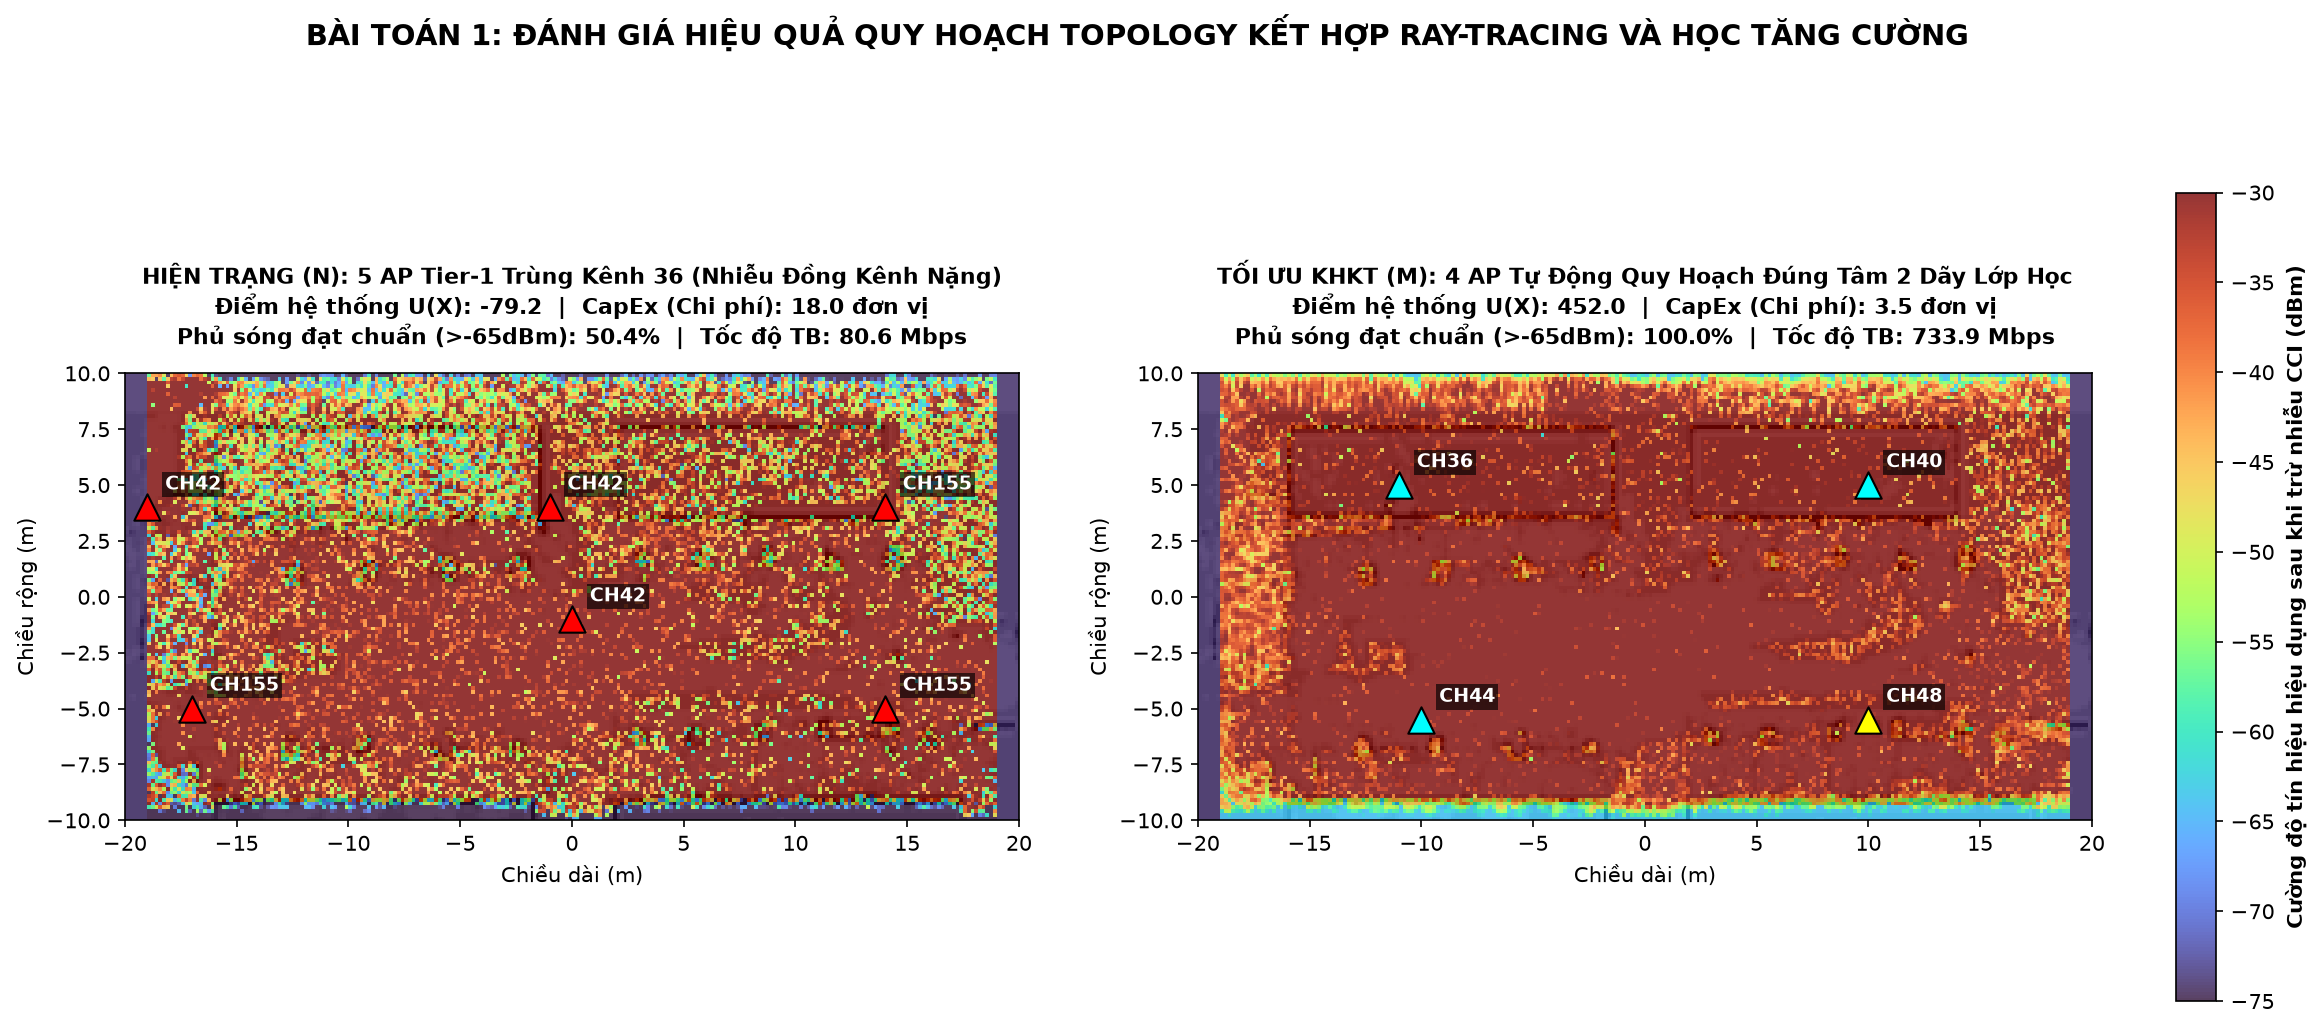

In [25]:
# Cấu trúc: (x, y, tx_dBm, channel, bw_mhz, tier_cost)
# Tier-1: cost = 3.0
# Tier-2: cost = 1.0
# Tier-3: cost = 0.5

# Hiện trạng (N): 2 AP đắt tiền, phát max công suất, trùng kênh gây nhiễu nặng
current_aps = [
    (-19, 4, 20.0, 42, 20, 3.0),
    ( 0, -1, 20.0, 42, 20, 3.0),
    (-1, 4, 20.0, 42, 20, 3.0),
    ( 14, 4, 20.0, 155, 20, 3.0),
    ( 14, -5, 20.0, 155, 20, 3.0),
    (-17, -5, 20.0, 155, 20, 3.0)
] 

optimized_aps, cached_fields = auto_optimize_ap_placement()

fig, axes = plt.subplots(1, 2, figsize=(18, 7), dpi=150)

# Khai báo lại không gian để vẽ
extent_bounds = [-SX/2, SX/2, -SY/2, SY/2]

scenarios = [
    (current_aps, False, "HIỆN TRẠNG (N): 5 AP Tier-1 Trùng Kênh 36 (Nhiễu Đồng Kênh Nặng)"),
    (optimized_aps, True, "TỐI ƯU KHKT (M): 4 AP Tự Động Quy Hoạch Đúng Tâm 2 Dãy Lớp Học")
]

for ax, (aps_config, ai_flag, label) in zip(axes, scenarios):
    diel, rssi, sinr, metrics = simulate_evaluate_topology(
        aps_config, is_ai_enabled=ai_flag, cached_fields=cached_fields
    )
    
    # Phản ánh đúng tác hại của Nhiễu đồng kênh (CCI) lên bản đồ nhiệt:
    # Khi SINR < 15 dB (do các AP trùng Kênh 36 đè sóng nhau), chất lượng tín hiệu thực tế bị sụt giảm mạnh
    cci_degradation = np.maximum(0.0, (16.0 - sinr) * 1.8)
    effective_qos_dbm = rssi - cci_degradation
    
    # Làm mờ vùng rìa ngoài khuôn viên tường bao trường học để tập trung thị giác vào bên trong tòa nhà
    x_lin = np.linspace(-SX/2, SX/2, diel.shape[0])[:, None]
    y_lin = np.linspace(-SY/2, SY/2, diel.shape[1])[None, :]
    outside_school = (np.abs(x_lin) > 19.0) | (y_lin < -13.5) | (y_lin > 10.5)
    
    # Gán màu đen/tím thẫm (-74 dBm) cho phần rác không gian bên ngoài tòa nhà
    effective_qos_dbm[outside_school] = -74.0
    
    # 1. Vẽ khung tường
    ax.imshow(diel.T, cmap='binary', origin='lower', extent=extent_bounds)
    
    # 2. Phủ Heatmap Chất lượng Tín hiệu Thực tế
    im = ax.imshow(effective_qos_dbm.T, cmap='turbo', alpha=0.80, vmin=-75, vmax=-30, origin='lower', extent=extent_bounds)
    
    # 3. Chấm vị trí các AP
    for (x, y, tx, ch, bw, cost) in aps_config:
        marker_color = 'red' if cost == 3.0 else ('cyan' if cost == 1.0 else 'yellow')
        ax.scatter(x, y, c=marker_color, edgecolors='black', s=160, marker='^', zorder=5)
        ax.text(x + 0.8, y + 0.8, f"CH{ch}", color='white', fontsize=9, fontweight='bold', 
                bbox=dict(facecolor='black', alpha=0.65, edgecolor='none', pad=1.5), zorder=6)
        
    # 4. In chỉ số định lượng U(X)
    title_text = (
        f"{label}\n"
        f"Điểm hệ thống U(X): {metrics['score']:.1f}  |  CapEx (Chi phí): {metrics['capex']} đơn vị\n"
        f"Phủ sóng đạt chuẩn (>-65dBm): {metrics['coverage_%']:.1f}%  |  Tốc độ TB: {metrics['avg_tput_mbps']:.1f} Mbps"
    )
    ax.set_title(title_text, fontsize=10.5, fontweight='bold', pad=14)
    ax.set_xlabel("Chiều dài (m)")
    ax.set_ylabel("Chiều rộng (m)")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.04)
cbar.set_label("Cường độ tín hiệu hiệu dụng sau khi trừ nhiễu CCI (dBm)", fontweight='bold')

plt.suptitle("BÀI TOÁN 1: ĐÁNH GIÁ HIỆU QUẢ QUY HOẠCH TOPOLOGY KẾT HỢP RAY-TRACING VÀ HỌC TĂNG CƯỜNG", 
             fontsize=14, fontweight='900', y=1.05)
plt.show()